# Which health programmes should be prioritized?

This chart ranks programmes by job postings per study place. Higher values indicate more observed job postings relative to the number of places. The three highest-ranked programmes are highlighted. The dashed line marks one posting per study place. This is an indicator for comparison, not proof of a workforce shortage.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

ROOT = Path.cwd()
if not (ROOT / "data/eval").exists():
    ROOT = ROOT.parent

ranks = pd.read_csv(ROOT / "data/eval/ranking_ranks.csv", index_col="programme")
plot_data = ranks.sort_values("postings_per_place", ascending=True)
colors = ["#D97941" if rank <= 3 else "#B8C2CC" for rank in plot_data["rank_method"]]

plt.rcParams.update({
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

FIGURES = ROOT / "figures"
FIGURES.mkdir(exist_ok=True)

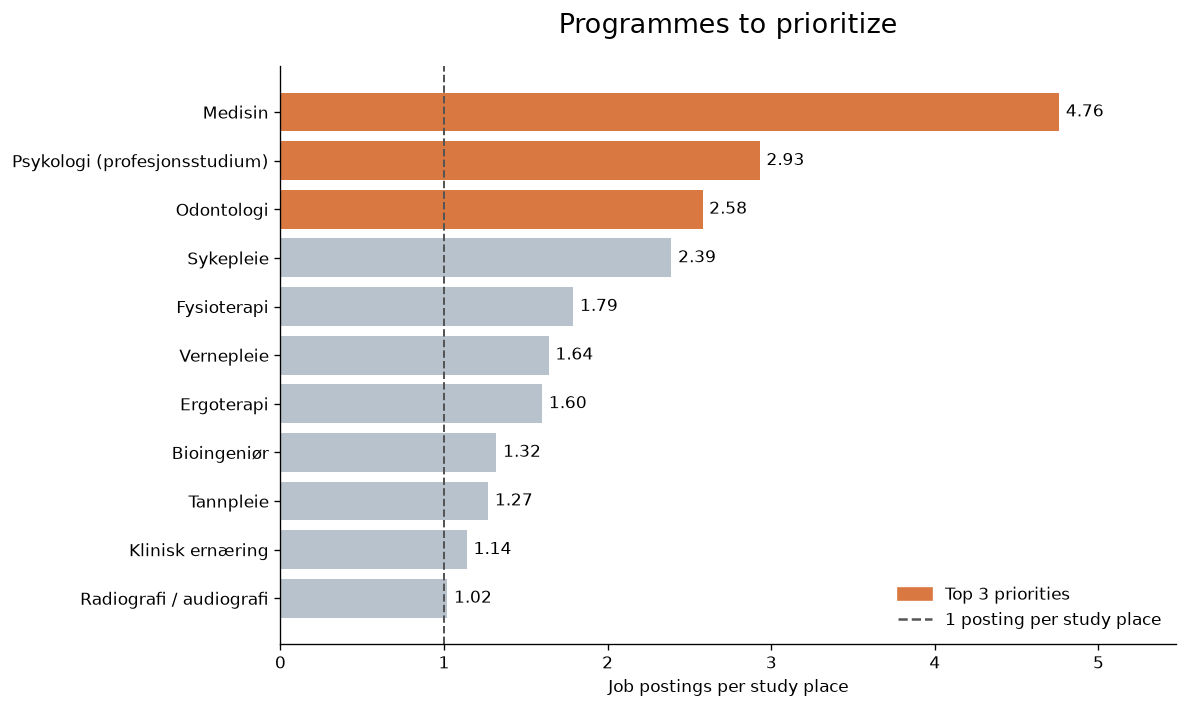

In [2]:
fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(
    plot_data.index,
    plot_data["postings_per_place"],
    color=colors,
)

ax.bar_label(bars, fmt="%.2f", padding=4)
ax.set_xlim(0, plot_data["postings_per_place"].max() * 1.15)
ax.axvline(1, color="#555555", linestyle="--", linewidth=1.2)
ax.set_title("Programmes to prioritize", fontsize=16, pad=20)
ax.set_xlabel("Job postings per study place")
ax.set_ylabel("")
ax.legend(
    handles=[
        Patch(color="#D97941", label="Top 3 priorities"),
        Line2D([0], [0], color="#555555", linestyle="--", label="1 posting per study place"),
    ],
    loc="lower right",
    frameon=False,
)

fig.tight_layout()
fig.savefig(FIGURES / "programmes_to_prioritize.png", bbox_inches="tight", dpi=200)
plt.show()